<a href="https://colab.research.google.com/github/CooL-Legend/CSCI544-DLM/blob/main/notebooks/LLaDA_Sudoku_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LLaDA Sudoku on Colab Pro

Run the GitHub project with a persistent model copy in Google Drive. Choose **Runtime → Change runtime type → GPU → L4 or A100** (subject to availability), then run the cells in order. Start with one puzzle.

The first session downloads about 16 GB of weights to Drive. Later sessions reuse those files. Each fresh runtime still needs to read the weights into GPU memory. The optional copy to `/content` speeds repeated model loads within a session; it uses runtime disk space, not another Drive copy.

For this **private GitHub repository**, open the notebook through Colab's GitHub tab after authorizing GitHub, or upload this `.ipynb` file to Colab. The clone cell separately needs a fine-grained GitHub token with **Contents: read** access to this repository. Store it in Colab **Secrets** as `GITHUB_TOKEN` and allow notebook access, or enter it into the hidden prompt. The token is never written to the clone URL, repository, or notebook output.


In [1]:
import torch

if not torch.cuda.is_available():
    raise RuntimeError("Select an L4 or A100 GPU runtime, then reconnect.")
gpu = torch.cuda.get_device_properties(0)
print(f"GPU: {gpu.name} | GPU memory: {gpu.total_memory / 2**30:.1f} GiB")
if gpu.total_memory < 20 * 2**30:
    raise RuntimeError("This notebook uses unquantized BF16 weights. Choose an L4/A100 runtime with more GPU memory; a 16 GB T4 is too small for this setup.")
if not torch.cuda.is_bf16_supported():
    raise RuntimeError("This GPU does not support the configured BF16 inference.")


GPU: NVIDIA L4 | GPU memory: 22.0 GiB


## 1. Get the code from GitHub
This cell clones the repository, or updates an existing clean checkout without discarding changes.


In [2]:
from pathlib import Path
import getpass
import os
import subprocess
import sys
import tempfile

REPOSITORY = "CooL-Legend/CSCI544-DLM"
BRANCH = "main"
REPO_URL = f"https://github.com/{REPOSITORY}.git"
REPO_DIR = Path("/content/CSCI544-DLM")

if REPO_DIR.exists():
    if not (REPO_DIR / ".git").is_dir():
        raise RuntimeError(f"{REPO_DIR} exists but is not a Git checkout. Choose another REPO_DIR.")
    existing_url = subprocess.check_output(["git", "-C", str(REPO_DIR), "remote", "get-url", "origin"], text=True).strip()
    if existing_url != REPO_URL:
        raise RuntimeError("The existing checkout belongs to a different repository.")
    git_args = ["-C", str(REPO_DIR), "pull", "--ff-only", "origin", BRANCH]
else:
    git_args = ["clone", "--branch", BRANCH, "--single-branch", REPO_URL, str(REPO_DIR)]

def run_git(token=None):
    env = {**os.environ, "GIT_TERMINAL_PROMPT": "0"}
    with tempfile.TemporaryDirectory() as tmp:
        if token:
            askpass = Path(tmp) / "askpass.py"
            askpass.write_text(
                "#!/usr/bin/env python3\nimport os, sys\n"
                "print('x-access-token' if 'username' in sys.argv[1].lower() else os.environ['COLAB_GH_TOKEN'])\n"
            )
            askpass.chmod(0o700)
            env.update(GIT_ASKPASS=str(askpass), COLAB_GH_TOKEN=token)
        return subprocess.run(["git", "-c", "credential.helper=", *git_args], env=env, capture_output=True, text=True)

result = run_git()
if result.returncode:
    from google.colab import userdata
    try:
        token = userdata.get("GITHUB_TOKEN")
    except Exception:
        token = None
    if not token:
        token = getpass.getpass("GitHub token with read access to this private repository: ")
    try:
        result = run_git(token)
    finally:
        del token
if result.returncode:
    raise RuntimeError(result.stderr.strip() or "GitHub clone/update failed.")
print(f"Code ready: {REPO_DIR}")
print("Commit:", subprocess.check_output(["git", "-C", str(REPO_DIR), "rev-parse", "--short", "HEAD"], text=True).strip())


Code ready: /content/CSCI544-DLM
Commit: d53d903


## 2. Install dependencies
Keep Colab’s CUDA-enabled PyTorch. Model execution uses a fresh Python process so it sees these installed package versions.


In [3]:
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(REPO_DIR / "requirements-colab.txt")], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '-r', '/content/CSCI544-DLM/requirements-colab.txt'], returncode=0)

## 3. Mount Drive and choose the run size
Keep at least **20 GB of free Google Drive storage** for the model and dataset, with extra room for results. Colab Pro and Drive storage are separate allowances.

Keep `NUM_SAMPLES = 1` for verification. Then run the three-puzzle length comparison below and inspect its results before increasing the sample count.

Set `COPY_MODEL_TO_RUNTIME = False` to load directly from Drive. The default keeps the persistent copy on Drive and stages model files on the runtime disk for loading.


In [4]:
from google.colab import drive

drive.mount("/content/drive")
DRIVE_ROOT = Path("/content/drive/MyDrive/CSCI544-DLM")
DRIVE_MODEL_DIR = DRIVE_ROOT / "models/LLaDA-8B-Instruct"
RUNTIME_MODEL_DIR = Path("/content/models/LLaDA-8B-Instruct")
COPY_MODEL_TO_RUNTIME = True
NUM_SAMPLES = 1

DRIVE_ROOT.mkdir(parents=True, exist_ok=True)
os.environ["HF_HUB_CACHE"] = str(DRIVE_ROOT / "cache/hub")
os.environ["HF_DATASETS_CACHE"] = str(DRIVE_ROOT / "cache/datasets")
MODEL_PATH = RUNTIME_MODEL_DIR if COPY_MODEL_TO_RUNTIME else DRIVE_MODEL_DIR
print("Persistent files:", DRIVE_ROOT)


Mounted at /content/drive
Persistent files: /content/drive/MyDrive/CSCI544-DLM


## 4. Check the data and write this run’s configuration
The first dataset preparation may process all one million rows before selecting your requested sample. The CSV columns are explicitly strings to preserve leading zeros.


In [5]:
import yaml

config = yaml.safe_load((REPO_DIR / "configs/sudoku.yaml").read_text())
config["data"].update(num_samples=NUM_SAMPLES, cache_dir=os.environ["HF_DATASETS_CACHE"])
config["model"].update(model_path=str(MODEL_PATH), device="cuda", local_files_only=True)
config["output_dir"] = str(DRIVE_ROOT / "results")
config["provenance"] = {
    "git_commit": subprocess.check_output(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], text=True).strip(),
    "model_revision": "08b83a6feb34df1a6011b80c3c00c7563e963b07",
}
RUN_CONFIG = Path("/content/sudoku-run.yaml")
RUN_CONFIG.write_text(yaml.safe_dump(config, sort_keys=False))
subprocess.run([sys.executable, "-u", str(REPO_DIR / "Llada-Sudoku/run_sudoku.py"), "--config", str(RUN_CONFIG), "--dataset-only"], check=True)


CompletedProcess(args=['/usr/bin/python3', '-u', '/content/CSCI544-DLM/Llada-Sudoku/run_sudoku.py', '--config', '/content/sudoku-run.yaml', '--dataset-only'], returncode=0)

## 5. Cache the model on Drive
Download the tokenizer, model configuration, Python model implementation, and all six weight shards. A fixed model revision keeps experiments consistent. Hugging Face checks its download metadata and reuses unchanged files on subsequent sessions; keep the model directory's hidden `.cache` folder.

If a download is interrupted, rerun this cell. If it reports a missing file or Drive quota problem, resolve that before proceeding. No model weights are committed to GitHub.


In [6]:
command = [sys.executable, "-u", str(REPO_DIR / "scripts/cache_model.py"), "--drive-dir", str(DRIVE_MODEL_DIR)]
if COPY_MODEL_TO_RUNTIME:
    command += ["--runtime-dir", str(RUNTIME_MODEL_DIR)]
subprocess.run(command, check=True)


CompletedProcess(args=['/usr/bin/python3', '-u', '/content/CSCI544-DLM/scripts/cache_model.py', '--drive-dir', '/content/drive/MyDrive/CSCI544-DLM/models/LLaDA-8B-Instruct', '--runtime-dir', '/content/models/LLaDA-8B-Instruct'], returncode=0)

## Config Updater

In [7]:
config["data"]["num_samples"] = 3

config["generation"].update(
    gen_length=256,
    steps=256,
    block_length=128,
    temperature=0.0,
    remasking="low_confidence",
)

# Dynamically construct the experiment name
gen = config["generation"]
temp_str = f"{gen['temperature']:g}"  # Formats 0.0 to 0
remask_str = gen['remasking'].replace('_confidence', 'conf')
exp_name = f"gen{gen['gen_length']}-steps{gen['steps']}-blk{gen['block_length']}-temp{temp_str}-{remask_str}"

# Update output directory to include the experiment name
config["output_dir"] = str(DRIVE_ROOT / "results" / exp_name)

RUN_CONFIG.write_text(yaml.safe_dump(config, sort_keys=False))
print(f"Experiment output directory: {config['output_dir']}\n")
print(RUN_CONFIG.read_text())


Experiment output directory: /content/drive/MyDrive/CSCI544-DLM/results/gen256-steps256-blk128-temp0-lowconf

data:
  num_samples: 3
  cache_dir: /content/drive/MyDrive/CSCI544-DLM/cache/datasets
model:
  model_path: /content/models/LLaDA-8B-Instruct
  device: cuda
  dtype: bfloat16
  local_files_only: true
generation:
  steps: 256
  gen_length: 256
  block_length: 128
  temperature: 0.0
  remasking: low_confidence
output_dir: /content/drive/MyDrive/CSCI544-DLM/results/gen256-steps256-blk128-temp0-lowconf
provenance:
  git_commit: d53d9033dd767b20247e343acc4346454a7625bb
  model_revision: 08b83a6feb34df1a6011b80c3c00c7563e963b07



## 6. Verify one puzzle
Keep `NUM_SAMPLES = 1` initially. The model loads once for this invocation, and each puzzle's raw response and metrics are saved to Drive. `status: completed` means inference finished, not that Sudoku was solved.

This cell identifies the newly created run so the inspection cells cannot silently select an older saved result. Interrupted runs retain completed predictions; automatic resume is not implemented.


In [8]:
# Clear the selected run before starting, including when rerunning this cell.
latest = None
first_record = None
RESULTS_ROOT = Path(config["output_dir"])
previous_runs = set(RESULTS_ROOT.glob("*/metrics.json"))
subprocess.run([sys.executable, "-u", str(REPO_DIR / "Llada-Sudoku/run_sudoku.py"), "--config", str(RUN_CONFIG)], check=True)
new_runs = set(RESULTS_ROOT.glob("*/metrics.json")) - previous_runs
if len(new_runs) != 1:
    raise RuntimeError("Could not identify exactly one new run. Inspect the result folders manually.")
latest = new_runs.pop().parent
print("This run:", latest)


This run: /content/drive/MyDrive/CSCI544-DLM/results/gen256-steps256-blk128-temp0-lowconf/20260920T193627098945Z


## 7. Inspect the verification result
An unparseable response receives zero exact and cell accuracy. Completion, clue preservation, and Sudoku validity are reported separately. A complete grid can still be wrong.

The chart keeps each line of an incomplete numeric response in its original row. Missing cells remain blank. Complete parsed grids are checked against clues and Sudoku rules; conflicts are flagged without repairing the answer.


In [15]:
import json

if latest is None:
    raise RuntimeError("Run the verification cell successfully before inspecting its results.")
print("Results:", latest)
print(json.dumps(json.loads((latest / "metrics.json").read_text()), indent=2))

print("\n--- All Predictions ---")
with (latest / "predictions.jsonl").open() as handle:
    for line in handle:
        record = json.loads(line)
        print(f"\nPrediction for Puzzle Index {record.get('index', 'Unknown')}:")
        print(json.dumps(record, indent=2))


Results: /content/drive/MyDrive/CSCI544-DLM/results/gen256-steps256-blk128-temp0-lowconf/20260920T193627098945Z
{
  "status": "completed",
  "requested": 3,
  "processed": 3,
  "exact_accuracy": 0.0,
  "cell_accuracy": 0.20164609053497942,
  "completion_rate": 0.3333333333333333,
  "clue_preservation_rate": 0.3333333333333333,
  "sudoku_validity_rate": 0.0
}

--- All Predictions ---

Prediction for Puzzle Index 0:
{
  "index": 0,
  "puzzle": "009083400005179802823005700107000605200560179604900003971030504000400917000001300",
  "solution": "719283456465179832823645791197328645238564179654917283971832564382456917546791328",
  "num_blanks": 40,
  "raw_output": "",
  "prediction": "",
  "parse_success": false,
  "generated_digit_count": 0,
  "exact": false,
  "correct_cells": 0,
  "clues_preserved": false,
  "valid_sudoku": false
}

Prediction for Puzzle Index 1:
{
  "index": 1,
  "puzzle": "540000000670092000002051060000000510054000020000510000010070000030009000000005370",
  "solution": "

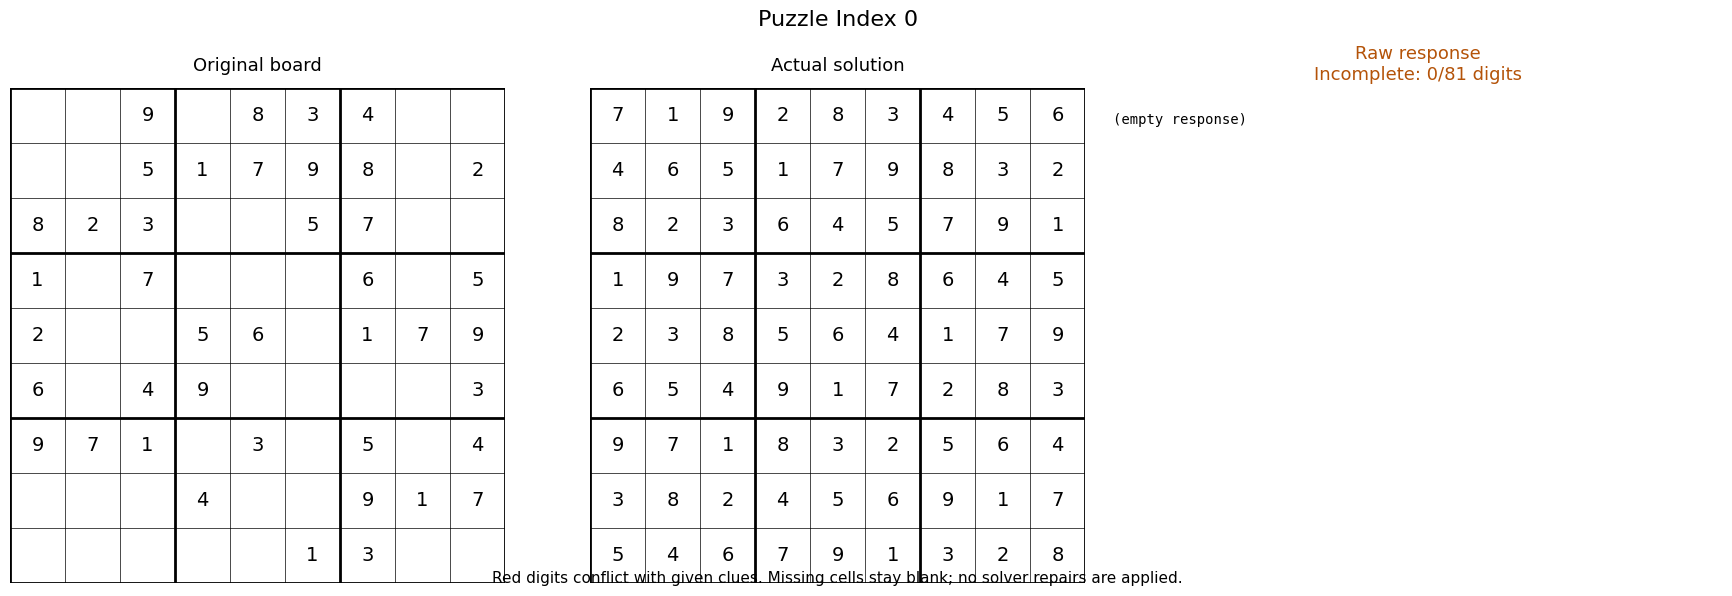

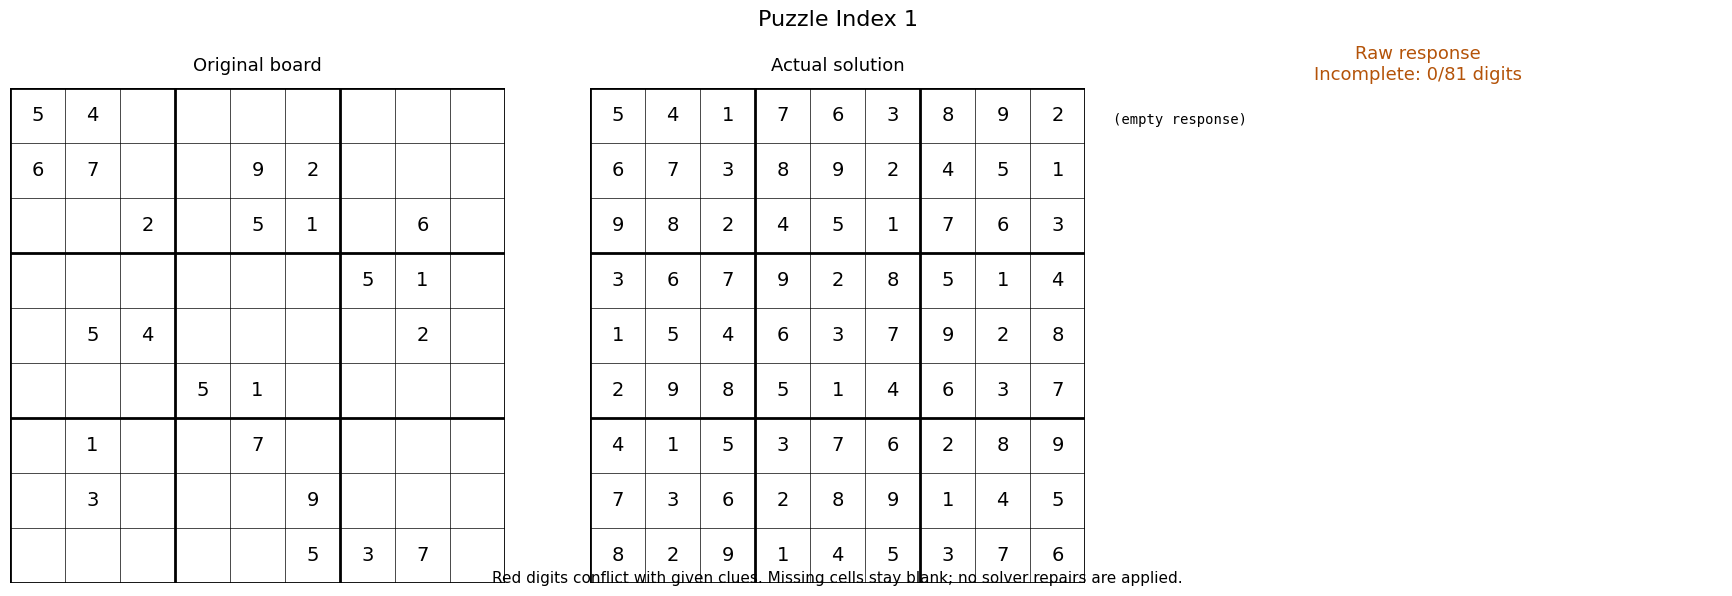

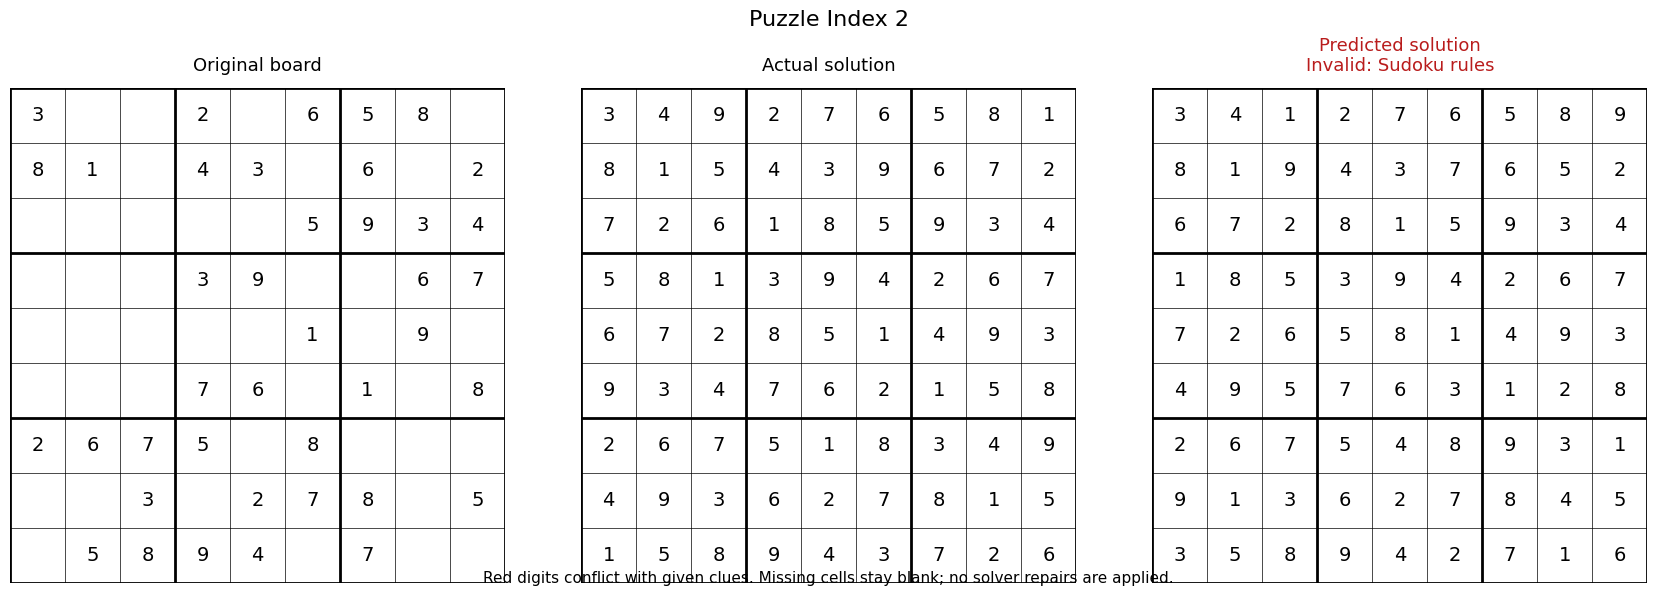

In [14]:
import importlib
import matplotlib.pyplot as plt
import json

module_dir = str(REPO_DIR / "Llada-Sudoku")
if module_dir not in sys.path:
    sys.path.insert(0, module_dir)
# Reload helpers when the GitHub checkout was updated in an existing runtime.
import run_sudoku
import sudoku_visualization
importlib.reload(run_sudoku)
importlib.reload(sudoku_visualization)

# Read all records from the current run and plot them
with (latest / "predictions.jsonl").open() as handle:
    for line in handle:
        current_record = json.loads(line)
        fig = sudoku_visualization.plot_prediction(current_record)
        fig.suptitle(f"Puzzle Index {current_record['index']}", fontsize=16)
        fig.tight_layout()
        fig.subplots_adjust(top=0.85)  # Add spacing between title and plots
        plt.show()
        plt.close(fig)


## 10. Increase the sample count only after review
If the setup works and the results justify a larger evaluation, change `NUM_SAMPLES` to 10 or 100 in step 3, rerun step 4 to write the configuration, and rerun steps 6–7. The length comparison remains fixed at the first three puzzles. To use a different generation length for a larger run, change `config["generation"]["gen_length"]` in step 4 before writing `RUN_CONFIG`.

### Notes and references
- This is LLaDA-only evaluation. Sudoku rules validate generated answers; no solver fills, repairs, or replaces them.
- The parser accepts exactly 81 digits in the range 1–9 after removing whitespace, or a standalone contiguous 81-digit answer embedded in text. It does not truncate extra digits or pad partial answers. Unparseable output has an empty `prediction`, zero matching cells, and false validation flags.
- Exact accuracy compares all 81 digits with the reference. Cell accuracy is matching cells divided by `81 × processed puzzles`. Completion, clue-preservation, and Sudoku-validity rates divide their respective passing counts by processed puzzles.
- Raw numeric lines that cannot fit within nine rows of nine columns are shown as text, not reshaped into a misleading grid.
- Saved notebook outputs are cleared in Git. Rerun cells to obtain results from your Colab session.
- [LLaDA](https://github.com/ML-GSAI/LLaDA) · [Model](https://huggingface.co/GSAI-ML/LLaDA-8B-Instruct) · [Dataset](https://huggingface.co/datasets/certen/Sudoku-1M-Puzzles)
- [Persistent Hugging Face downloads](https://huggingface.co/docs/huggingface_hub/guides/download#download-files-to-a-local-folder) · [Colab resource and storage FAQ](https://research.google.com/colaboratory/faq.html)
